# Predictor

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2

In [2]:
def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)
    
def show_points(coords, labels, ax, marker_size=375):
    pos_points = coords[labels==1]
    neg_points = coords[labels==0]
    ax.scatter(pos_points[:, 0], pos_points[:, 1], color='green', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)
    ax.scatter(neg_points[:, 0], neg_points[:, 1], color='red', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)   
    
def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0,0,0,0), lw=2))    


## Example image

In [3]:
image = cv2.imread('images/truck.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

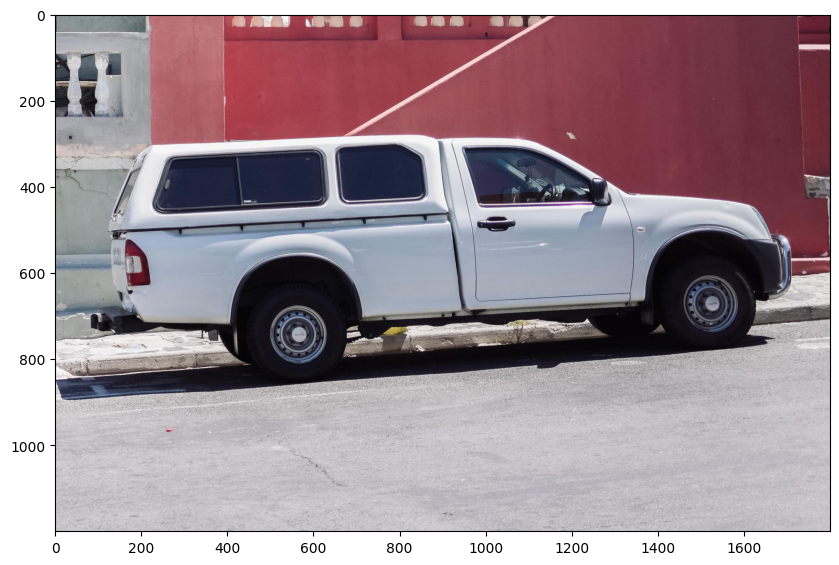

In [4]:
plt.figure(figsize=(10,10))
plt.imshow(image)
plt.axis('on')
plt.show()

## Selecting objects with SAM

In [5]:
import sys
sys.path.append("..")
from sam_tvm import SamPredictor, sam_model_registry

sam_checkpoint = "../checkpoints/sam_vit_b_01ec64.pth"
model_type = "vit_b"
device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)

predictor = SamPredictor(sam, 'cuda')

[01:24:08] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:08] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:08] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:08] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:08] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:08] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:08] /project/include/tvm/topi/transform

In [6]:
predictor.set_image(image)

In [7]:
input_point = np.array([[500, 375]])
input_label = np.array([1])

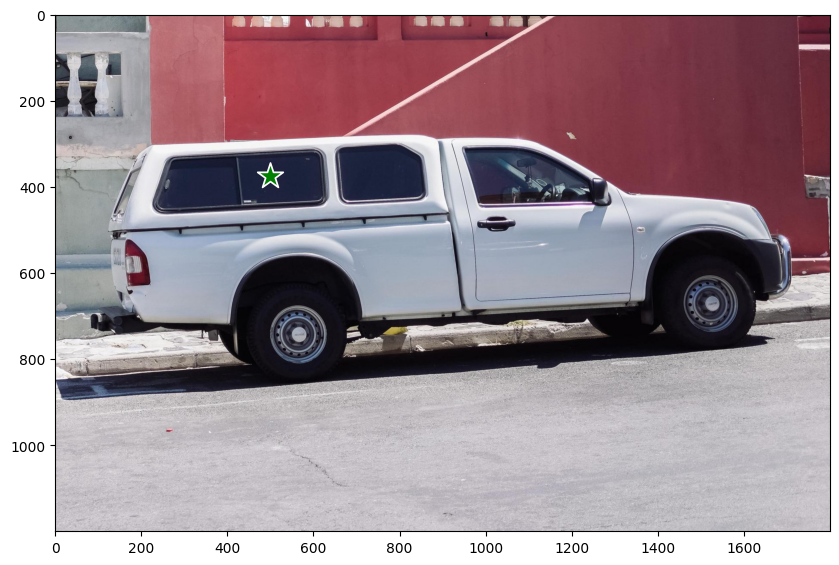

In [8]:
plt.figure(figsize=(10,10))
plt.imshow(image)
show_points(input_point, input_label, plt.gca())
plt.axis('on')
plt.show()  

In [9]:
masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True,
)

[01:24:38] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:38] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:38] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:38] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:38] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:38] /project/include/tvm/topi/transform.h:1261: Warning: Fast mode segfaults when there are out-of-bounds indices. Make sure input indices are in bound
[01:24:38] /project/include/tvm/topi/transform

In [10]:
masks.shape  # (number_of_masks) x H x W

(3, 1200, 1800)

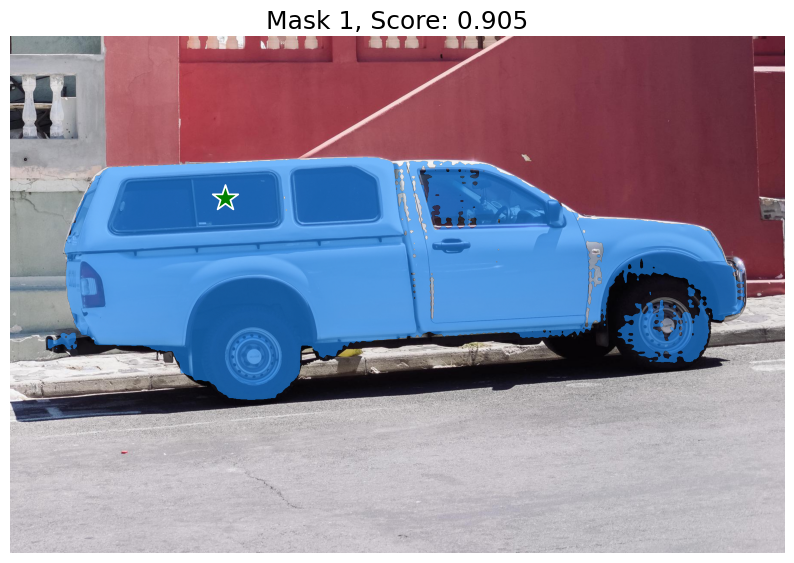

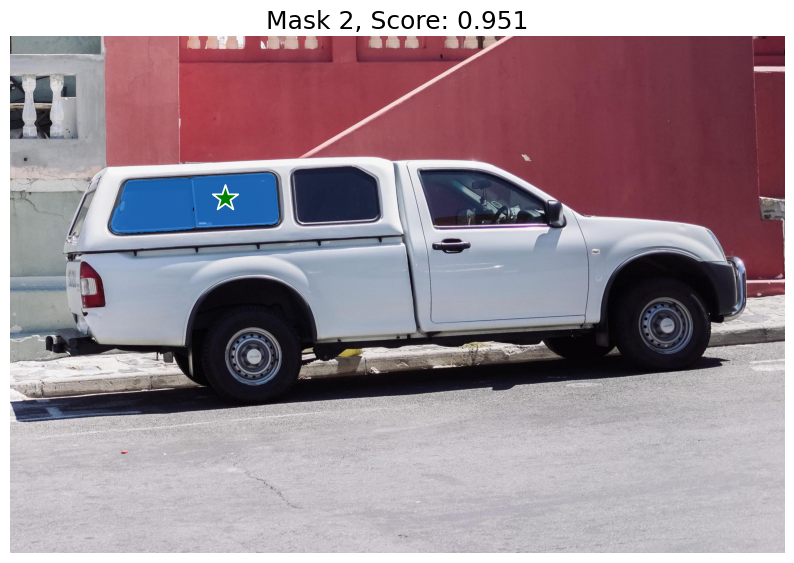

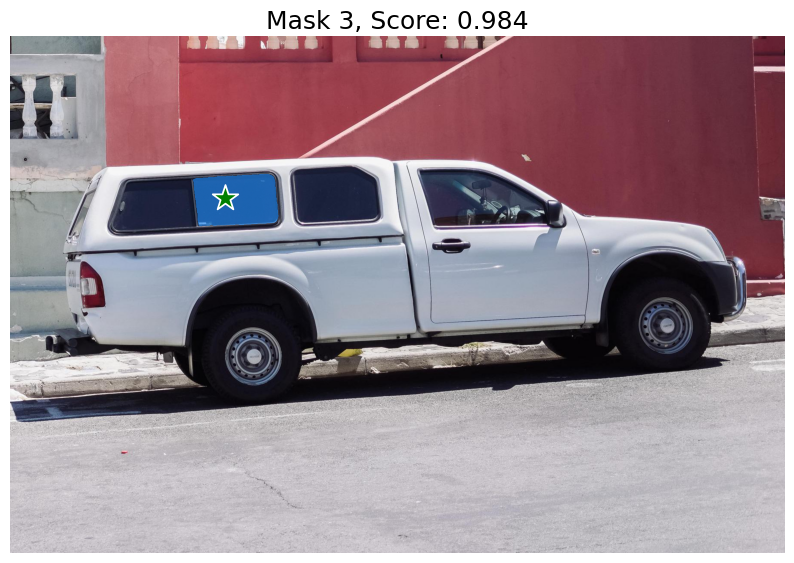

In [11]:
for i, (mask, score) in enumerate(zip(masks, scores)):
    plt.figure(figsize=(10,10))
    plt.imshow(image)
    show_mask(mask, plt.gca())
    show_points(input_point, input_label, plt.gca())
    plt.title(f"Mask {i+1}, Score: {score:.3f}", fontsize=18)
    plt.axis('off')
    plt.show()  
  

## Specifying a specific object with additional points

In [18]:
input_point = np.array([[500, 375], [1125, 625]])
input_label = np.array([1, 1])

mask_input = logits[np.argmax(scores), :, :]  # Choose the model's best mask

In [ ]:
masks, _, _ = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    mask_input=mask_input[None, :, :],
    multimask_output=False,
)

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
show_mask(masks, plt.gca())
show_points(input_point, input_label, plt.gca())
plt.axis('off')
plt.show() 

## Specifying a specific object with a box

In [12]:
input_box = np.array([425, 600, 700, 875])

In [21]:
masks, _, _ = predictor.predict(
    point_coords=None,
    point_labels=None,
    box=input_box[None, :],
    multimask_output=False,
)

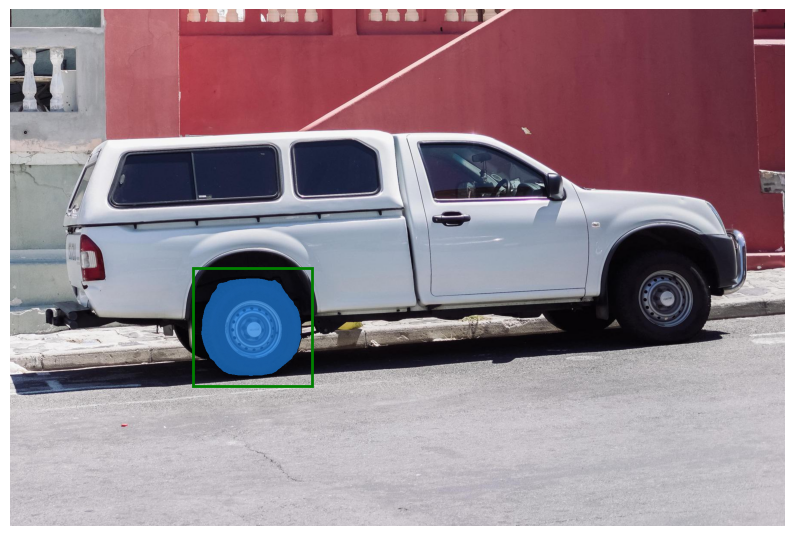

In [22]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
show_mask(masks[0], plt.gca())
show_box(input_box, plt.gca())
plt.axis('off')
plt.show()

## Combining points and boxes

In [15]:
input_box = np.array([425, 600, 700, 875])
input_point = np.array([[575, 750]])
input_label = np.array([0])

In [19]:
masks, _, _ = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    box=input_box,
    multimask_output=False,
)

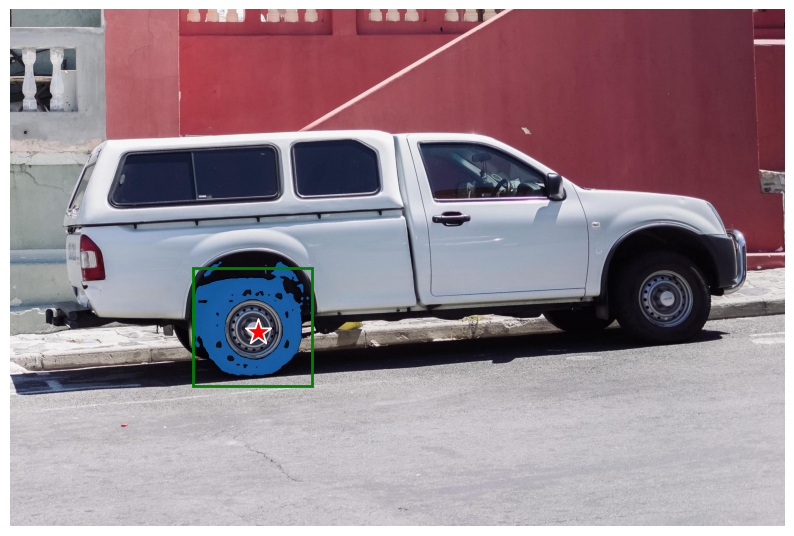

In [20]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
show_mask(masks[0], plt.gca())
show_box(input_box, plt.gca())
show_points(input_point, input_label, plt.gca())
plt.axis('off')
plt.show()